# Sydney Metro City Line: Impact on Sydney Trains Usage

**A data science project analysing Opal trip data to see how the new Chatswood -> Sydenham metro line changed Metro and train usage, and using regression models to predict the effect of the Bankstown metro conversion.**

## Project Overview
This project uses monthly Opal trip counts from Transport for NSW to compare Sydney Metro and Sydney Trains usage before and after the Chatswood -> Sydenham metro line opened on 19 August 2024. The Metro, and the four train lines that cross over with it (T1, T4, T8, T9), are compared for the Adult, Child/Youth, and Senior/Pensioner card types. A Linear Regression and a Decision Tree Regressor are then trained on the four train lines and used to predict trips on the T3 Bankstown Line, which was the next line being converted to metro when this project was created.

The project is a university data science assignment.

**Key findings**
* Metro trips for the three card types increased by 155% (6.4M -> 16.5M) after the new line opened, with the Senior/Pensioner card having the biggest percentage increase (+197%) and the Adult card the biggest increase in trips (+7.5M).
* Trips on the four crossover train lines decreased by 15% (69.8M -> 59.1M). The biggest decrease was the Adult card on the T1 North Shore & Western Line (-6.0M, -27%).
* Linear Regression gave the best test result (r2 0.82) after one-hot encoding the card types, but neither model predicted the Bankstown line well (r2 below 0), because the models don't know which line they are predicting and the Sydenham -> Bankstown section closed for the metro conversion on 30th September 2024.

**Tools:** Python, pandas, matplotlib, scikit-learn (Linear Regression, Decision Tree Regressor)

**Data:** Opal trip counts by month, line and card types for Sydney Trains (`train.csv`) and by month and card type for Sydney Metro (`metro.csv`), January 2024 to March 2025, from the Transport for NSW Open Data Hub.

**How to run:** Put `train.csv` and `metro.csv` in the same folder as this notebook, install `numpy pandas matplotlib scikit-learn`, and run all cells.

## 1. Question & Justification

### Questions: 

1. How did Sydney Metro usage change after the Chatswood -> Sydenham extension opened, comparing Feb-Jul 2024 (before) with Sep 2024-Feb 2025 (after)?
2. Did the train lines that cross the metro (T1, T4, T8, T9) lose riders, and which lines and card types changed the most?
3. Can trends on those lines predict what happens to the T3 Bankstown Line as it is converted to metro and whether it would be beneficial for Adult, Child/Youth, and Senior/Pensioner riders?

### Justification:
The questions will be addressed to determine the effects of the metro line on train lines in Sydney, Australia, analysing how the addition of new lines will affect the current trains. This is a beneficial analysis as it helps determine if the development of further metro lines is supported by data, supporting or preventing the resources and time that'll be used in development.


August 2024 is left out of both periods as the line opened partway through the month (19 August), so it would mix before and after data.


## 2. Data clean-up, Preprocessing, Preparation and Exploration


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model, metrics, model_selection, tree
from sklearn.tree import DecisionTreeRegressor


df_train = pd.read_csv('train.csv')
df_metro = pd.read_csv('metro.csv')

metro_opening = pd.to_datetime('2024-08-19')

# Filters the train data to only the T3 Bankstown line
df_bankstown =  df_train[df_train['Line'].str.startswith('T3') & (df_train['Card Type'].isin(['Adult','Child/Youth','Senior/Pensioner']))]

# Filters the train data showing only the Adult, Child, and Senior card types, that the trip value is above 0, and only the lines that cross over with the metro (T1, T4, T8, T9)
df_train = df_train[(df_train['Card Type'].isin(['Adult','Child/Youth','Senior/Pensioner'])) & (df_train['Trip'] > 0) & 
                    (df_train['Line'].str.contains('T1|T9|T8|T4'))]

# Filters the metro data to the chosen card types, and that there have been trips taken
df_metro = df_metro[(df_metro['Card Type'].isin(['Adult','Child/Youth','Senior/Pensioner'])) & (df_metro['Trip'] > 0)]

# Sets Bankstown train data to only months in the pre, and post periods
df_bankstownpre = df_bankstown[(df_bankstown['Year_Month'].between('2024-02', '2024-07'))].copy()
df_bankstownpost = df_bankstown[(df_bankstown['Year_Month'].between('2024-09', '2025-02'))].copy()

# Sets train data to only months in the pre, and post periods
df_trainpre = df_train[(df_train['Year_Month'].between('2024-02', '2024-07'))]
df_trainpost = df_train[(df_train['Year_Month'].between('2024-09', '2025-02'))]

# Sets metro data to only months in the pre, and post periods
df_metropre = df_metro[(df_metro['Year_Month'].between('2024-02', '2024-07'))]
df_metropost = df_metro[(df_metro['Year_Month'].between('2024-09', '2025-02'))]

# Combines all pre, and post period tables for bankstown, train and metro
df_bankstownprepost = pd.concat([df_bankstownpre, df_bankstownpost])
df_trainprepost = pd.concat([df_trainpre, df_trainpost])
df_metroprepost = pd.concat([df_metropre, df_metropost])

# Copy of trainprepost for visualisation
df_copytrainprepost = df_trainprepost.copy()

df_bankstownpre.head(40)


,Year_Month,Card Type,Line,Trip
244,2024-02,Adult,T3 Bankstown Line,1124788.0
284,2024-02,Child/Youth,T3 Bankstown Line,58589.0
417,2024-02,Senior/Pensioner,T3 Bankstown Line,255168.0
489,2024-03,Adult,T3 Bankstown Line,1181411.0
529,2024-03,Child/Youth,T3 Bankstown Line,59520.0
652,2024-03,Senior/Pensioner,T3 Bankstown Line,269528.0
720,2024-04,Adult,T3 Bankstown Line,955312.0
760,2024-04,Child/Youth,T3 Bankstown Line,63267.0
883,2024-04,Senior/Pensioner,T3 Bankstown Line,215781.0
953,2024-05,Adult,T3 Bankstown Line,1156850.0


## 3. Modelling

### Baseline Model: Linear Regression

In [2]:
# Making a new column to track time numerically, incrementing each month in date order
months_count = sorted(df_trainprepost['Year_Month'].unique())

months = {}
i = 1

for month in months_count:
    months[month] = i
    i += 1

# Adding the Time Column to both trainprepost, and bankstown so they both have the same metric
df_trainprepost['Time'] = df_trainprepost['Year_Month'].map(months)
df_bankstownprepost['Time'] = df_bankstownprepost['Year_Month'].map(months)

# Create numeric column for Card Types so it can be used in training, and prediction
# Card Types is a category not a ranking, so each card type gets its own 0/1 column
# Adult is the baseline, when both Is_Child and Is_Senior are 0

for df in [df_trainprepost, df_bankstownprepost]:
    df['Is_Child'] = (df['Card Type'] == 'Child/Youth').astype(int)
    df['Is_Senior'] = (df['Card Type'] == 'Senior/Pensioner').astype(int)

features = ['Is_Child', 'Is_Senior', 'Time'] 

# Splits the data into training and test sets
train, test = model_selection.train_test_split(df_trainprepost, test_size=0.2, random_state=42)

# Creates a X and Y for training
X_train = train[features]
y_train = train['Trip']

model = linear_model.LinearRegression()

# Fits the training model
model.fit(X_train, y_train)

# Using the fitted model to predict Bankstown trips
df_bankstownprepost['Predicted_Trip'] = model.predict(df_bankstownprepost[features])

# Predictions put into variables for the evaluation section
y_pred = model.predict(df_bankstownprepost[features])
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(test[features])

# Shows the bankstownprepost first 20 rows, removing decimals from Trip and Predicted Trip
df_bankstownprepost.head(20).style.format({'Trip': '{:.0f}','Predicted_Trip': '{:.0f}'})

,Year_Month,Card Type,Line,Trip,Time,Is_Child,Is_Senior,Predicted_Trip
244,2024-02,Adult,T3 Bankstown Line,1124788,1,0,0,2262020
284,2024-02,Child/Youth,T3 Bankstown Line,58589,1,1,0,275724
417,2024-02,Senior/Pensioner,T3 Bankstown Line,255168,1,0,1,574667
489,2024-03,Adult,T3 Bankstown Line,1181411,2,0,0,2236762
529,2024-03,Child/Youth,T3 Bankstown Line,59520,2,1,0,250466
652,2024-03,Senior/Pensioner,T3 Bankstown Line,269528,2,0,1,549410
720,2024-04,Adult,T3 Bankstown Line,955312,3,0,0,2211505
760,2024-04,Child/Youth,T3 Bankstown Line,63267,3,1,0,225209
883,2024-04,Senior/Pensioner,T3 Bankstown Line,215781,3,0,1,524152
953,2024-05,Adult,T3 Bankstown Line,1156850,4,0,0,2186247


### Analysis/Prediction Model: Decision Tree (Regression)

In [3]:
# Trains a regression tree with a max depth of 4
regressor = DecisionTreeRegressor(random_state=42, max_depth=4)
regressor.fit(X_train, y_train)

# Predictions 
df_bankstownprepost['Predicted_Trip_Tree'] = regressor.predict(df_bankstownprepost[features])
y_pred_tree = regressor.predict(df_bankstownprepost[features])
y_pred_tree_train = regressor.predict(X_train)
y_pred_tree_test = regressor.predict(test[features])

## 4. Rationale & Comparison

### Rationale Baseline Model:
* Linear Regression was chosen as the baseline model as it's a regression model that provides a numeric outcome, allowing for the prediction of Bankstown's train trips. Linear Regression is effective as it handles trends over time based on specific fitted variables, allowing for the train line data such as Time and Card Type to be used in fitting. Additionally, Linear Regression provides interpretable results for evaluating the accuracy and behaviour of the data through metrics such as r2, MAE, and RMSE.


### Rationale Analysis/Prediction Model
* A Decision Tree was chosen in addition to Linear Regression as the Decision Tree Regressor gives additional analysis by handling non-linear relationships, to check for any patterns that the Linear Regressor may have missed. Comparing the two models gives the analysis and predictions more accountability, making the results more reliable and comprehensive.

### Advantages

**Linear Regression**:
* Easy to implement
* Computationally efficient making it execute quickly
* Easily interpreted
* Good baseline model

**Decision Tree (Regressor)**:
* Handles Non-Linear Relationships
* No need for scaling
* Less affected by outliers
* Easily interpreted
* Handles numerical data 

### Disadvantages
**Linear Regression**:
* Struggles with outliers
* Assumes a linear increase, struggling with non-linear relationships
* Overly simple, doesn't handle complexity well

**Decision Tree (Regressor):**
* Prone to overfitting if tree size is not limited
* High variance and instability, where minor changes in the data cause major changes to the tree
* Not designed for linear relationships, approximating them in steps which makes it less effective on linear data

## 5. Visualisation & Performance Evaluation

### Comparing Pre and Post data of Metro and Trains

In [4]:
# Grouping all months into one total pre and post to better view the total difference 
metropre_grouped = df_metropre.groupby(['Operator', 'Card Type'])['Trip'].sum().reset_index()
metropost_grouped = df_metropost.groupby(['Operator', 'Card Type'])['Trip'].sum().reset_index()

# Merged both metro pre and post grouped dataframes, and added a Difference and Percentage column using the pre and post data 
metro_diff = pd.merge(metropre_grouped, metropost_grouped, on=['Card Type', 'Operator'], suffixes=('_pre', '_post'))
metro_diff['Difference'] = metro_diff['Trip_post'] - metro_diff['Trip_pre']
metro_diff['Percent_Change'] = metro_diff['Difference'] / metro_diff['Trip_pre'] * 100

metro_diff.style.format({'Trip_pre': '{:,.0f}', 'Trip_post': '{:,.0f}', 'Difference': '{:+,.0f}', 'Percent_Change': '{:+.1f}%'})

,Operator,Card Type,Trip_pre,Trip_post,Difference,Percent_Change
0,Sydney Metro,Adult,"5,000,771","12,546,531","+7,545,760",+150.9%
1,Sydney Metro,Child/Youth,"582,700","1,358,710","+776,010",+133.2%
2,Sydney Metro,Senior/Pensioner,"858,365","2,549,042","+1,690,677",+197.0%


### Metro usage pre and post Chatswood -> Sydenham Line : Visualisation

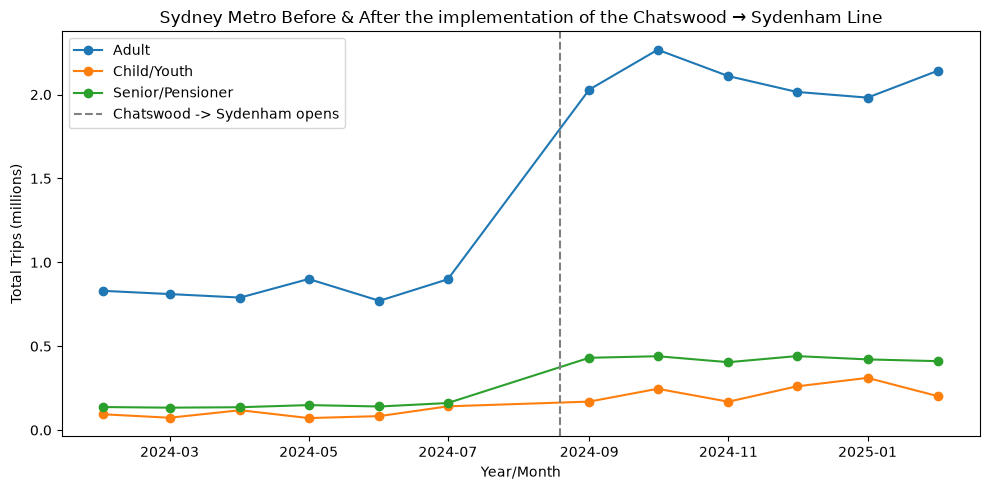

In [5]:
# Ungrouped months for better visualisation
# Create a array of chosen card types
card_types = ['Adult', 'Child/Youth', 'Senior/Pensioner']
df_metroprepost['Year_Month'] = pd.to_datetime(df_metroprepost['Year_Month'])

plt.figure(figsize=(10,5))

# Loop through card types adding them to a line plot using the metroprepost dataset
for card in card_types:
    card_data = df_metroprepost[(df_metroprepost['Card Type'] == card)]
    plt.plot(card_data['Year_Month'], card_data['Trip'], marker='o', label=card)

# Marks the opening of the new line (August is left out of both periods)
plt.axvline(metro_opening, color='grey', linestyle='--', label='Chatswood -> Sydenham opens')

# Label, Titling and adding a legend to the line plot 
plt.xlabel('Year/Month')
plt.ylabel('Total Trips (millions)')
plt.title('Sydney Metro Before & After the implementation of the Chatswood → Sydenham Line')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: '%.1f' % (x / 1e6)))
plt.legend()
plt.tight_layout()
plt.show()

Answer: The difference above shows that with the addition of the new metro extension Chatswood -> Sydenham all card types increased usage, with the Adult card increasing the most with an increase of 7,545,760 trips (+150.9%), and the Child/Youth card having the smallest increase of 776,010 trips (+133.2%). By percentage the Senior/Pensioner card increased the most, nearly tripling with an increase of 197.0%. In total, metro trips for the three card types went from 6,441,836 to 16,454,283 (+155.4%). 

In [6]:
# Grouping all months into one total pre and post to better view the total difference 
trainpre_grouped = df_trainpre.groupby(['Line', 'Card Type'])['Trip'].sum().reset_index()
trainpost_grouped = df_trainpost.groupby(['Line', 'Card Type'])['Trip'].sum().reset_index()

# Merged both train pre and post grouped dataframes, and added a Difference and Percent Change column using the pre and post data 
train_diff = pd.merge(trainpre_grouped, trainpost_grouped, on=['Card Type', 'Line'], suffixes=('_pre', '_post'))
train_diff['Difference'] = train_diff['Trip_post'] - train_diff['Trip_pre']
train_diff['Percent_Change'] = train_diff['Difference'] / train_diff['Trip_pre'] * 100

train_diff.style.format({'Trip_pre': '{:,.0f}', 'Trip_post': '{:,.0f}', 'Difference': '{:+,.0f}', 'Percent_Change': '{:+.1f}%'})

,Line,Card Type,Trip_pre,Trip_post,Difference,Percent_Change
0,T1 North Shore Line & T1 Western Line,Adult,"22,259,297","16,255,767","-6,003,530",-27.0%
1,T1 North Shore Line & T1 Western Line,Child/Youth,"1,287,252","1,069,063","-218,189",-16.9%
2,T1 North Shore Line & T1 Western Line,Senior/Pensioner,"3,808,833","3,215,310","-593,523",-15.6%
3,T4 Eastern Suburbs & Illawarra Line,Adult,"13,517,723","11,968,672","-1,549,051",-11.5%
4,T4 Eastern Suburbs & Illawarra Line,Child/Youth,"707,405","743,249","+35,844",+5.1%
5,T4 Eastern Suburbs & Illawarra Line,Senior/Pensioner,"2,945,819","2,870,407","-75,412",-2.6%
6,T8 Airport & South Line,Adult,"11,011,004","10,592,425","-418,579",-3.8%
7,T8 Airport & South Line,Child/Youth,"604,261","661,369","+57,108",+9.5%
8,T8 Airport & South Line,Senior/Pensioner,"1,907,187","2,021,210","+114,023",+6.0%
9,T9 Northern Line,Adult,"8,915,476","7,096,581","-1,818,895",-20.4%


In [7]:
# Total across all four lines for each card type, to see the overall change in train usage
train_total = train_diff.groupby('Card Type')[['Trip_pre', 'Trip_post', 'Difference']].sum().reset_index()
train_total['Percent_Change'] = train_total['Difference'] / train_total['Trip_pre'] * 100

train_total.style.format({'Trip_pre': '{:,.0f}', 'Trip_post': '{:,.0f}', 'Difference': '{:+,.0f}', 'Percent_Change': '{:+.1f}%'})

,Card Type,Trip_pre,Trip_post,Difference,Percent_Change
0,Adult,"55,703,500","45,913,445","-9,790,055",-17.6%
1,Child/Youth,"3,360,831","3,137,300","-223,531",-6.7%
2,Senior/Pensioner,"10,761,524","10,021,964","-739,560",-6.9%


Answer: The difference shows that with the addition of the new metro line Chatswood -> Sydenham overall train usage decreased by 15.4% (69,825,855 to 59,072,709 trips) with a select few cards and lines increasing. The biggest increase was seen in Senior/Pensioner on the T8 Airport & South Line with an increase of 114,023 (+6.0%), and the biggest decrease was seen in the Adult card on the T1 North Shore Line & T1 Western Line with a decrease of 6,003,530 (-27.0%). Overall the Adult card saw the most decrease in train usage out of all the card types, decreasing by 17.6% compared to 6.7% for Child/Youth and 6.9% for Senior/Pensioner. The T1 and T9 lines, which both run between Chatswood and the CBD like the new metro line, had the biggest decrease for the Adult card.

### Train usage pre and post Chatswood -> Sydenham Line : Visualisation

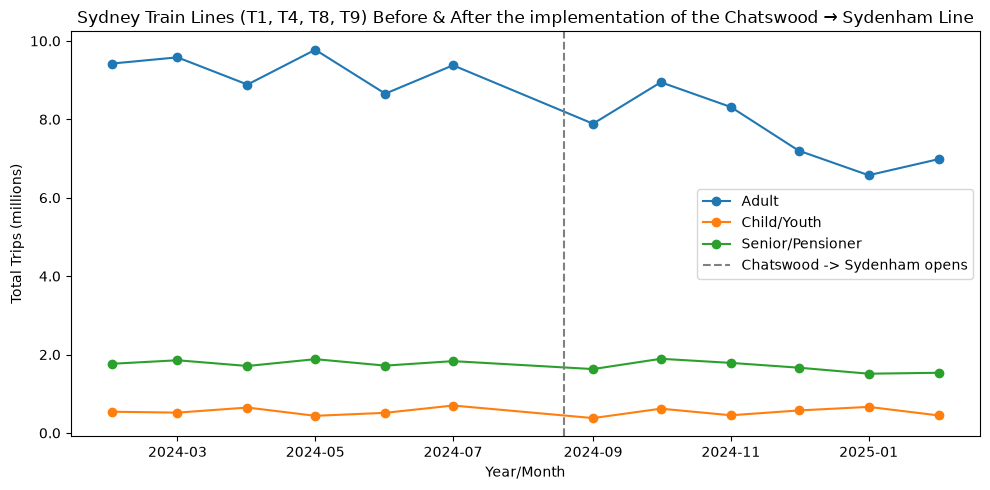

In [8]:
# Ungrouped months for better visualisation
# Create a array of chosen card types
card_types = ['Adult', 'Child/Youth', 'Senior/Pensioner']

# Adjusting Year_Month to datetime for better visualisation of months
df_copytrainprepost['Year_Month'] = pd.to_datetime(df_copytrainprepost['Year_Month'])

plt.figure(figsize=(10, 5))

# Loop through card types adding them to a line plot using the trainprepost dataset
for card in card_types:
    card_data = df_copytrainprepost[(df_copytrainprepost['Card Type'] == card)]
    # Groups all the lines into one total for each month 
    grouped = card_data.groupby(['Year_Month'])['Trip'].sum().reset_index()
    plt.plot(grouped['Year_Month'], grouped['Trip'], marker='o', label=card)

# marks the opening of the new line (August is left out of both periods)
plt.axvline(metro_opening, color='grey', linestyle='--', label='Chatswood -> Sydenham opens')

# Label, Titling and adding a legend to the line plot 
plt.xlabel('Year/Month')
plt.ylabel('Total Trips (millions)')
plt.title('Sydney Train Lines (T1, T4, T8, T9) Before & After the implementation of the Chatswood → Sydenham Line')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: '%.1f' % (x / 1e6)))
plt.legend()
plt.tight_layout()
plt.show()

### Linear Regression Evaluation

In [9]:

# calculates the r2, MAE, RMSE for the test data
r2 = metrics.r2_score(test['Trip'], y_pred_test)
mae = metrics.mean_absolute_error(test['Trip'], y_pred_test)
rmse = np.sqrt(metrics.mean_squared_error(test['Trip'], y_pred_test))

# print results
print('Test r2: %.4f Test mae: %.4f Test rmse: %.4f\n' % (r2, mae, rmse))

# calculates the r2, MAE, RMSE for the training data
r2_train = metrics.r2_score(y_train, y_pred_train)
mae_train = metrics.mean_absolute_error(y_train, y_pred_train)
rmse_train = np.sqrt(metrics.mean_squared_error(y_train, y_pred_train))
# prints results
print('Train r2: %.4f Train mae: %.4f Train rmse: %.4f\n' % (r2_train, mae_train, rmse_train))

# calculates the r2, MAE, RMSE for the Bankstown data
r2_bankstown = metrics.r2_score(df_bankstownprepost['Trip'], y_pred)
mae_bankstown = metrics.mean_absolute_error(df_bankstownprepost['Trip'], y_pred)
rmse_bankstown = np.sqrt(metrics.mean_squared_error(df_bankstownprepost['Trip'], y_pred))
# prints results
print('Bankstown r2: %.4f Bankstown mae: %.4f Bankstown rmse: %.4f\n' % (r2_bankstown, mae_bankstown, rmse_bankstown))


Test r2: 0.8229 Test mae: 217014.7086 Test rmse: 390632.0748

Train r2: 0.7937 Train mae: 269010.9884 Train rmse: 450704.0963

Bankstown r2: -3.1644 Bankstown mae: 555029.8913 Bankstown rmse: 796425.8178



Evaluation of Linear Regression Model: Both the test and train results fitted with the df_trainprepost dataset show no signs of overfitting or underfitting as the results are close across all three metrics (test r2 0.82, train r2 0.79), indicating good generalisation, with the MAE and RMSE showing a similar but large error window of around 200,000 to 450,000 trips for each. However the Bankstown line didn't predict well as the r2 was negative (-3.16), and the MAE and RMSE are much larger than training and test, indicating the linear regressor didn't predict the trends of Bankstown correctly.

### Decision Tree Regressor

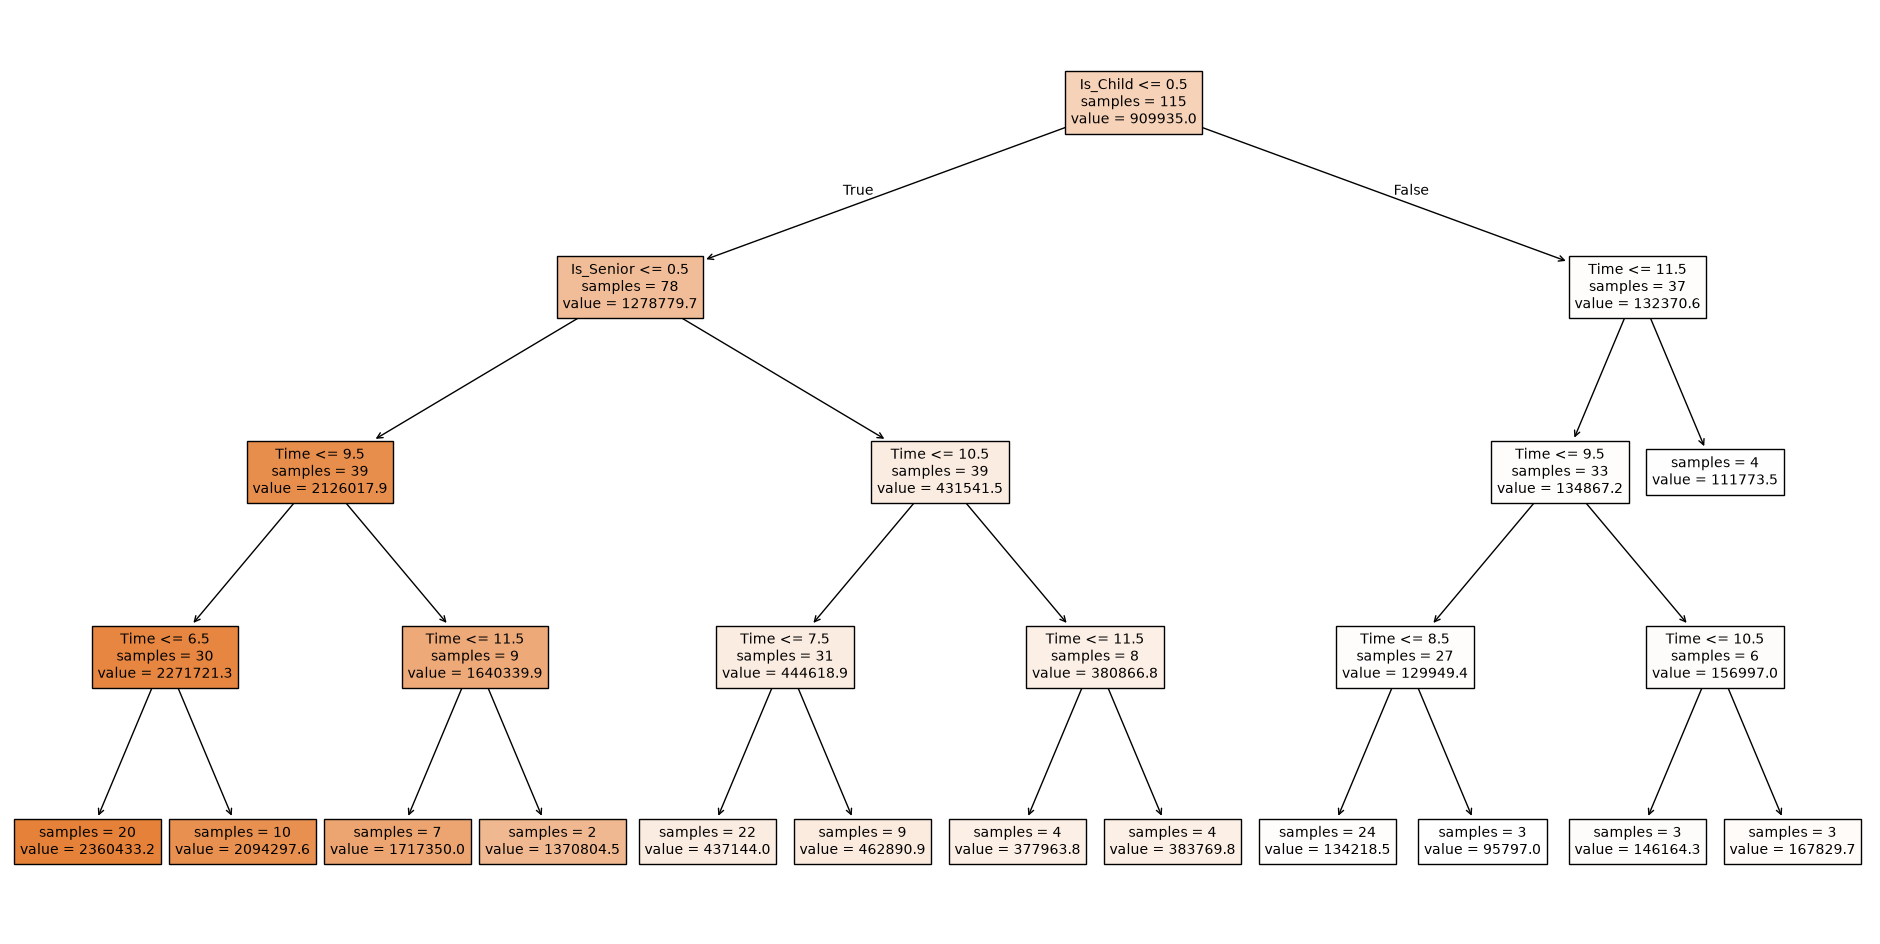

In [10]:
# Visualisation of the Decision Tree structure
# impurity=False hides the squared error in each box so the tree is easier to read
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(regressor, feature_names=features, filled=True, impurity=False, precision=1, fontsize=10, ax=ax)
plt.show()

In [11]:
# Evaluating the Decision Tree model with the testing data
r2_tree = metrics.r2_score(test['Trip'], y_pred_tree_test)
mae_tree = metrics.mean_absolute_error(test['Trip'], y_pred_tree_test)
rmse_tree = np.sqrt(metrics.mean_squared_error(test['Trip'], y_pred_tree_test))
print('Test r2: %.4f Test mae: %.4f Test rmse: %.4f\n' % (r2_tree, mae_tree, rmse_tree))

# Evaluating the Decision Tree model with the training data
r2_tree_train = metrics.r2_score(y_train, y_pred_tree_train)
mae_tree_train = metrics.mean_absolute_error(y_train, y_pred_tree_train)
rmse_tree_train = np.sqrt(metrics.mean_squared_error(y_train, y_pred_tree_train))
print('Train r2: %.4f Train mae: %.4f Train rmse: %.4f\n' % (r2_tree_train, mae_tree_train, rmse_tree_train))

# Evaluating the Decision Tree model with the Bankstown data
r2_tree_bankstown = metrics.r2_score(df_bankstownprepost['Trip'], y_pred_tree)
mae_tree_bankstown = metrics.mean_absolute_error(df_bankstownprepost['Trip'], y_pred_tree)
rmse_tree_bankstown = np.sqrt(metrics.mean_squared_error(df_bankstownprepost['Trip'], y_pred_tree))
print('Bankstown r2: %.4f Bankstown mae: %.4f Bankstown rmse: %.4f\n' % (r2_tree_bankstown, mae_tree_bankstown, rmse_tree_bankstown))


Test r2: 0.7720 Test mae: 236690.1855 Test rmse: 443251.5329

Train r2: 0.8164 Train mae: 244770.7028 Train rmse: 425087.2450

Bankstown r2: -2.9616 Bankstown mae: 545600.6902 Bankstown rmse: 776792.2033



Evaluation of Decision Tree: Similar to the Linear Regressor, both Test and Training are a good fit seen through the r2 scores (test 0.77, train 0.82), and all three metrics being similar. Compared to the Linear Regressor the tree fits the training data slightly better but the test data slightly worse, which is a small sign of overfitting even with the max depth of 4. However the Bankstown prediction also didn't fit well with a negative r2 score (-2.96), and large error scores in both MAE and RMSE, meaning it failed to predict accurately with the provided data. 

### Model Comparison

In [12]:
# Puts both models results side by side to compare them
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Linear Regression', 'Linear Regression', 'Decision Tree', 'Decision Tree', 'Decision Tree'],
    'Dataset': ['Train', 'Test', 'Bankstown', 'Train', 'Test', 'Bankstown'],
    'R2': [r2_train, r2, r2_bankstown, r2_tree_train, r2_tree, r2_tree_bankstown],
    'MAE': [mae_train, mae, mae_bankstown, mae_tree_train, mae_tree, mae_tree_bankstown],
    'RMSE': [rmse_train, rmse, rmse_bankstown, rmse_tree_train, rmse_tree, rmse_tree_bankstown]})

results.style.format({'R2': '{:.4f}', 'MAE': '{:,.0f}', 'RMSE': '{:,.0f}'})

,Model,Dataset,R2,MAE,RMSE
0,Linear Regression,Train,0.7937,"269,011","450,704"
1,Linear Regression,Test,0.8229,"217,015","390,632"
2,Linear Regression,Bankstown,-3.1644,"555,030","796,426"
3,Decision Tree,Train,0.8164,"244,771","425,087"
4,Decision Tree,Test,0.7720,"236,690","443,252"
5,Decision Tree,Bankstown,-2.9616,"545,601","776,792"


Both models perform similarly on the four train lines, with the Linear Regression performing slightly better on the test data. The tree structure above first splits on the card types then on Time, which is the same pattern the Linear Regression found. Both models have a negative r2 on Bankstown, meaning they predict worse than just using the average of the Bankstown trips.

## 6. Conclusion

In [13]:
# Percentage change between the before and after periods for the actual T3 trips and both models predictions
bankstown_pre = df_bankstownprepost[df_bankstownprepost['Year_Month'] <= '2024-07']
bankstown_post = df_bankstownprepost[df_bankstownprepost['Year_Month'] >= '2024-09']

for column, label in [('Trip', 'Actual'), ('Predicted_Trip', 'Linear Regression'), ('Predicted_Trip_Tree', 'Decision Tree')]:
    pre_total = bankstown_pre[column].sum()
    post_total = bankstown_post[column].sum()
    print('{}: before {:,.0f}  after {:,.0f}  change {:+.1f}%'.format(
        label, pre_total, post_total, (post_total - pre_total) / pre_total * 100))

Actual: before 8,547,459  after 3,867,639  change -54.8%
Linear Regression: before 17,537,880  after 14,810,069  change -15.6%
Decision Tree: before 17,590,774  after 14,465,949  change -17.8%


Overall through analysis, the addition of the new metro line caused increased usage of the metro, with the Adult card seeing the biggest increase in trips and the Senior/Pensioner card the biggest percentage increase. This increase also reduced usage of the train lines, with Adults having the biggest decrease on the T1 line, while Senior/Pensioners on the T8 line had the biggest increase.

Using this data, predictive models using Linear Regression and Decision Tree Regression were trained to determine if the development of a Bankstown metro extension would be beneficial. Both models predicted the Bankstown line usage would decrease after the metro opened (Linear Regression -15.6%, Decision Tree -17.8%), following the same trend as the other train lines. However, the r2, MAE, and RMSE showed that both models are poorly fitted to the Bankstown data and have high error windows. The actual Bankstown trips dropped 54.8%, as the Sydenham -> Bankstown section closed on 30th September 2024 for the metro conversion, which the models had no way of knowing about.

Based on the trends seen in the metro and train data, the Bankstown metro line would likely be beneficial for Adult, Child/Youth, and Senior/Pensioner riders, as all three card types increased their metro usage after the Chatswood -> Sydenham line opened. The trend on the Bankstown train line would likely follow the same trend seen on the T1, T4, T8 and T9 lines, where train usage decreases with the implementation of a new metro line, with the Adult card seeing the biggest decrease.